In [51]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sales = pd.read_csv("sales_data.csv")
customers = pd.read_csv("customer_churn.csv")

print("Sales dataset:")
display(sales.head())

print("Customer churn dataset:")
display(customers.head())

Sales dataset:


,Date,Product,Quantity,Price,Customer_ID,Region,Total_Sales
0,2024-01-01,Phone,7,37300,CUST001,East,261100
1,2024-01-02,Headphones,4,15406,CUST002,North,61624
2,2024-01-03,Phone,2,21746,CUST003,West,43492
3,2024-01-04,Headphones,1,30895,CUST004,East,30895
4,2024-01-05,Laptop,8,39835,CUST005,North,318680


Customer churn dataset:


,CustomerID,Tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,PaperlessBilling,SeniorCitizen,Churn
0,C00001,6,64,1540,One year,Credit Card,No,1,0
1,C00002,21,113,1753,Month-to-month,Electronic Check,Yes,1,0
2,C00003,27,31,1455,Two year,Credit Card,No,1,0
3,C00004,53,29,7150,Month-to-month,Electronic Check,No,1,0
4,C00005,16,185,1023,One year,Electronic Check,No,1,0


In [4]:
print("Sales shape:", sales.shape)
print("Sales columns:", sales.columns.tolist())

print("\nCustomer shape:", customers.shape)
print("Customer columns:", customers.columns.tolist())

print("\nSales information:")
sales.info()

print("\nCustomer information:")
customers.info()

NameError: name 'sales' is not defined

In [53]:
# Remove spaces from column names
sales.columns = sales.columns.str.strip()
customers.columns = customers.columns.str.strip()

# Check missing values
print("Missing values in sales:")
print(sales.isnull().sum())

print("\nMissing values in customers:")
print(customers.isnull().sum())

# Check duplicate rows
print("\nSales duplicates:", sales.duplicated().sum())
print("Customer duplicates:", customers.duplicated().sum())

Missing values in sales:
Date           0
Product        0
Quantity       0
Price          0
Customer_ID    0
Region         0
Total_Sales    0
dtype: int64

Missing values in customers:
CustomerID          0
Tenure              0
MonthlyCharges      0
TotalCharges        0
Contract            0
PaymentMethod       0
PaperlessBilling    0
SeniorCitizen       0
Churn               0
dtype: int64

Sales duplicates: 0
Customer duplicates: 0


In [54]:
sales = sales.drop_duplicates()
customers = customers.drop_duplicates()

In [55]:
total_revenue = sales["Total_Sales"].sum()
average_sale = sales["Total_Sales"].mean()
highest_sale = sales["Total_Sales"].max()
lowest_sale = sales["Total_Sales"].min()

print("Total Revenue:", total_revenue)
print("Average Sale:", round(average_sale, 2))
print("Highest Sale:", highest_sale)
print("Lowest Sale:", lowest_sale)

Total Revenue: 12365048
Average Sale: 123650.48
Highest Sale: 373932
Lowest Sale: 6540


In [56]:
product_sales = (
    sales.groupby("Product")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

display(product_sales)

Product
Laptop        3889210
Tablet        2884340
Phone         2859394
Headphones    1384033
Monitor       1348071
Name: Total_Sales, dtype: int64

In [57]:
product_quantity = (
    sales.groupby("Product")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

display(product_quantity)

Product
Laptop        136
Tablet        127
Phone         101
Monitor        66
Headphones     48
Name: Quantity, dtype: int64

In [58]:
filtered_sales = sales[
    (sales["Region"] == "North") &
    (sales["Total_Sales"] > 50000)
]

display(filtered_sales)

,Date,Product,Quantity,Price,Customer_ID,Region,Total_Sales
1,2024-01-02,Headphones,4,15406,CUST002,North,61624
4,2024-01-05,Laptop,8,39835,CUST005,North,318680
8,2024-01-09,Tablet,3,32791,CUST009,North,98373
17,2024-01-18,Tablet,4,19322,CUST018,North,77288
19,2024-01-20,Laptop,8,41749,CUST020,North,333992
22,2024-01-23,Laptop,9,29275,CUST023,North,263475
25,2024-01-26,Laptop,3,25948,CUST026,North,77844
27,2024-01-28,Tablet,7,43495,CUST028,North,304465
29,2024-01-30,Tablet,9,11902,CUST030,North,107118
36,2024-02-06,Phone,5,40177,CUST037,North,200885


In [59]:
sales["Date"] = pd.to_datetime(
    sales["Date"],
    errors="coerce"
)

sales["Year"] = sales["Date"].dt.year
sales["Month"] = sales["Date"].dt.month
sales["Day"] = sales["Date"].dt.day

sales["Product"] = (
    sales["Product"]
    .astype("string")
    .str.strip()
    .str.title()
)

display(sales.head())

,Date,Product,Quantity,Price,Customer_ID,Region,Total_Sales,Year,Month,Day
0,2024-01-01,Phone,7,37300,CUST001,East,261100,2024,1,1
1,2024-01-02,Headphones,4,15406,CUST002,North,61624,2024,1,2
2,2024-01-03,Phone,2,21746,CUST003,West,43492,2024,1,3
3,2024-01-04,Headphones,1,30895,CUST004,East,30895,2024,1,4
4,2024-01-05,Laptop,8,39835,CUST005,North,318680,2024,1,5


In [60]:
monthly_sales = (
    sales.groupby(["Year", "Month"])["Total_Sales"]
    .sum()
    .reset_index()
)

display(monthly_sales)

,Year,Month,Total_Sales
0,2024,1,4120524
1,2024,2,2656050
2,2024,3,4485006
3,2024,4,1103468


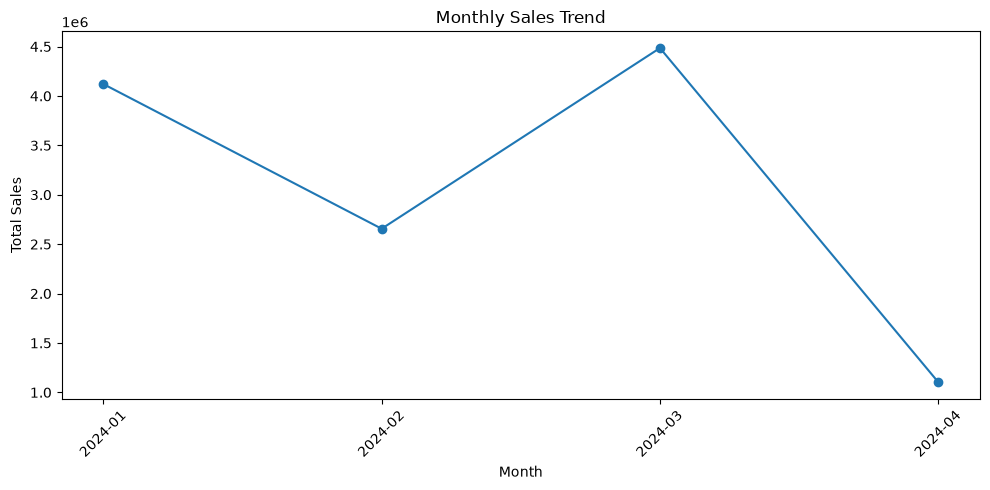

In [61]:
monthly_sales["Period"] = (
    monthly_sales["Year"].astype(str)
    + "-"
    + monthly_sales["Month"].astype(str).str.zfill(2)
)

plt.figure(figsize=(10, 5))
plt.plot(
    monthly_sales["Period"],
    monthly_sales["Total_Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [62]:
pivot_table = pd.pivot_table(
    sales,
    values="Total_Sales",
    index="Product",
    columns="Region",
    aggfunc="sum",
    fill_value=0
)

display(pivot_table)

Region,East,North,South,West
Product,,,,
Headphones,288361,107091,512168,476413
Laptop,221946,1798206,1373120,495938
Monitor,642870,397100,39924,268177
Phone,506828,489284,1471428,391854
Tablet,859634,1191954,341212,491540


In [63]:
print(customers["Churn"].value_counts(dropna=False))

Churn
0    447
1     53
Name: count, dtype: int64


In [64]:
churn_rate = customers["Churn"].mean() * 100

print("Customer churn rate:", round(churn_rate, 2), "%")

Customer churn rate: 10.6 %


In [65]:
churn_by_contract = pd.crosstab(
    customers["Contract"],
    customers["Churn"],
    normalize="index"
) * 100

display(churn_by_contract)

Churn,0,1
Contract,,
Month-to-month,79.411765,20.588235
One year,95.698925,4.301075
Two year,93.055556,6.944444


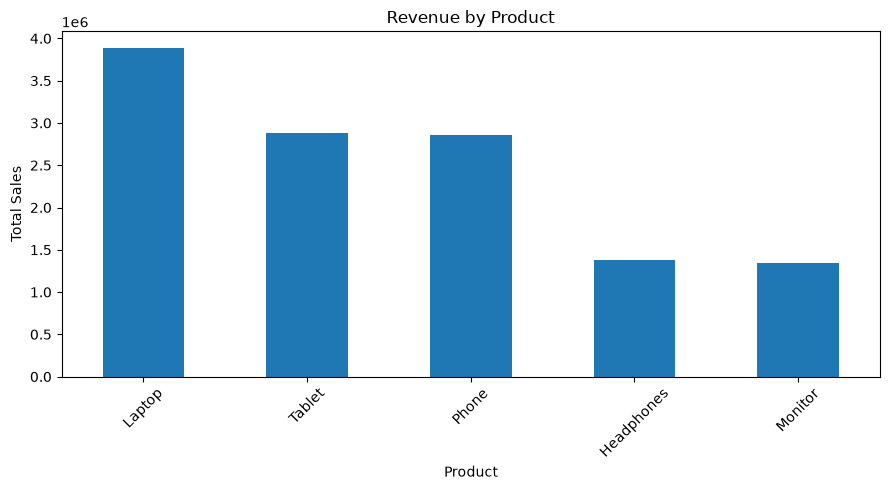

In [66]:
product_sales.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

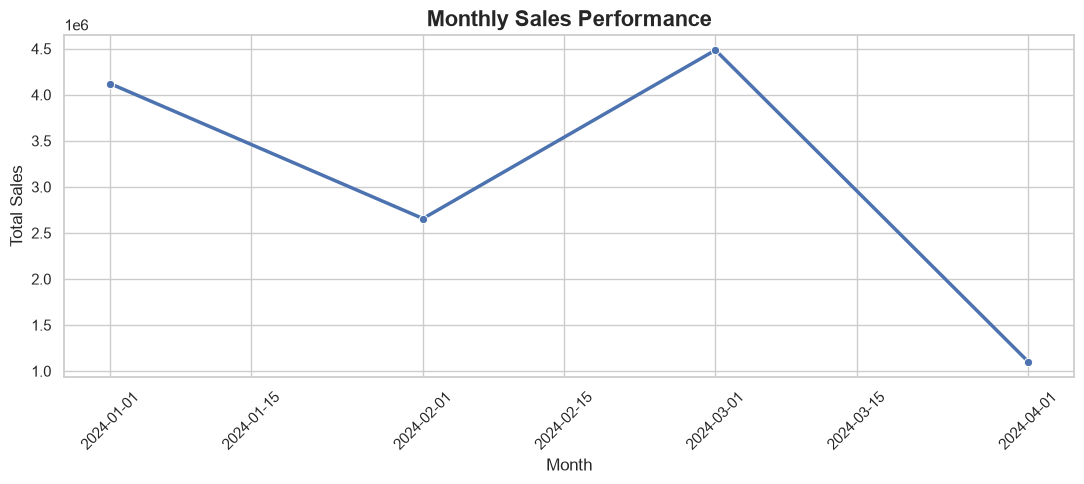

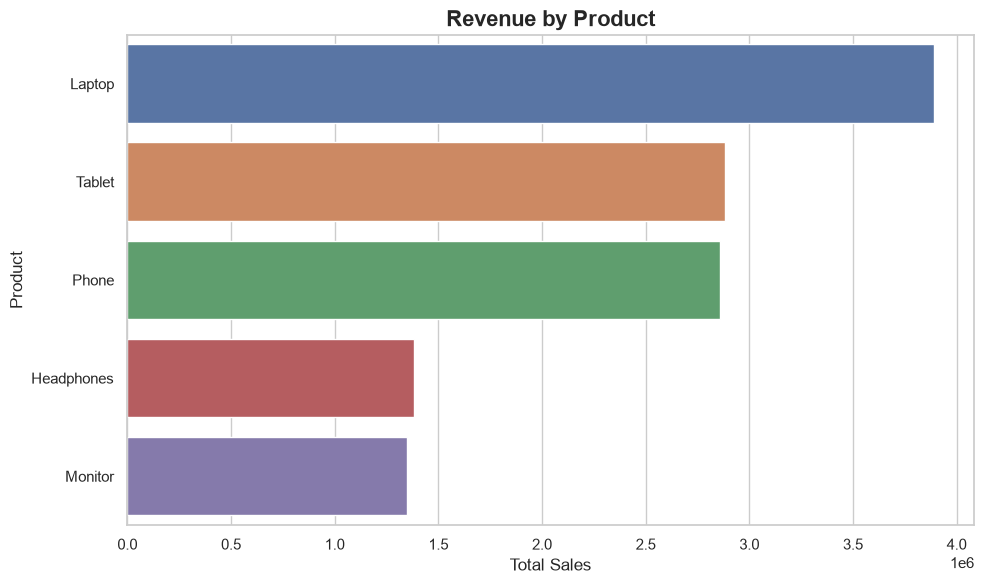

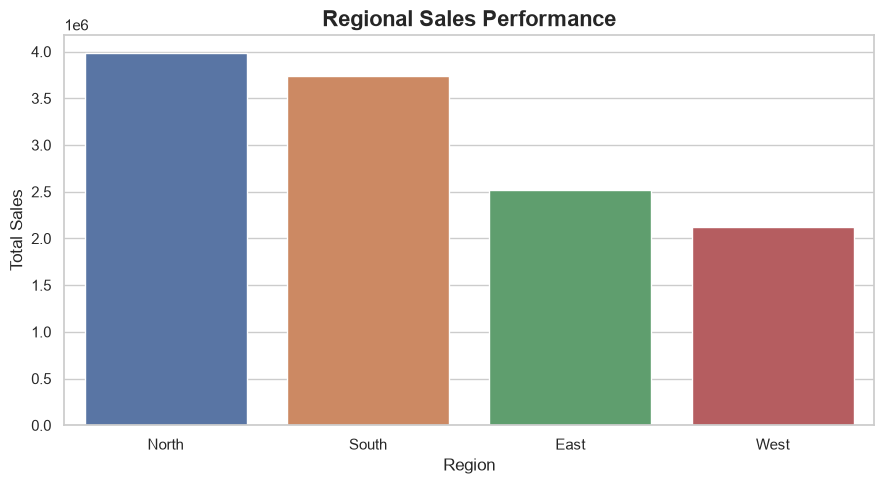

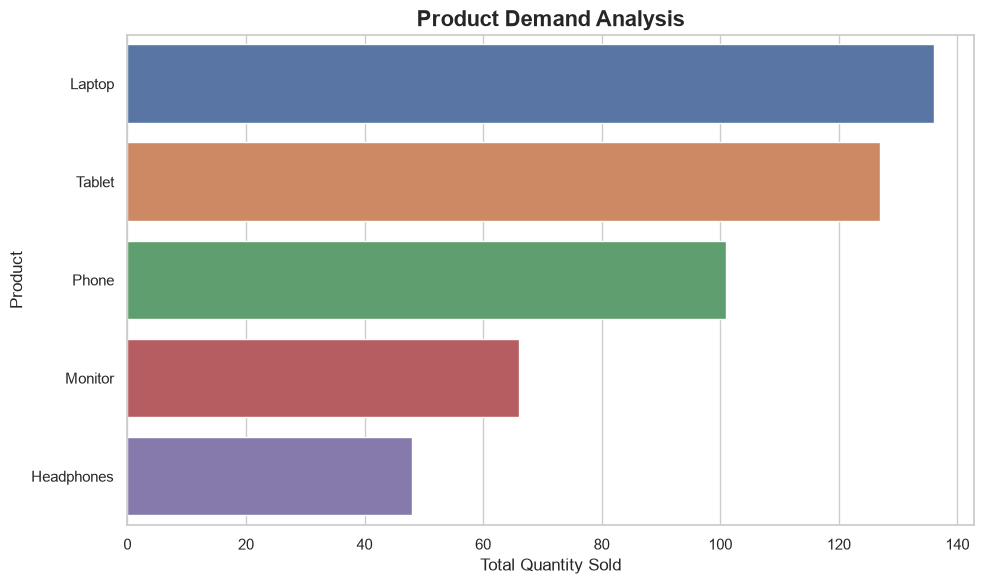

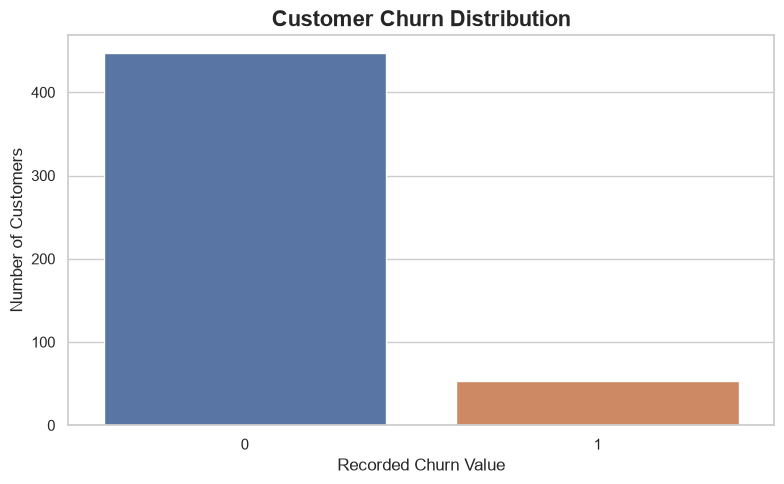

All available charts have been created and saved in the charts folder.


In [67]:

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Professional chart styling
sns.set_theme(style="whitegrid", context="notebook")

# Create a folder to save charts
os.makedirs("charts", exist_ok=True)

# Load datasets
sales = pd.read_csv("sales_data.csv")
customers = pd.read_csv("customer_churn.csv")

# Clean column names
sales.columns = sales.columns.str.strip()
customers.columns = customers.columns.str.strip()

# Prepare data types
sales["Date"] = pd.to_datetime(sales["Date"], errors="coerce")

for col in ["Quantity", "Price", "Total_Sales"]:
    sales[col] = pd.to_numeric(sales[col], errors="coerce")

# Remove records missing essential chart data
sales = sales.dropna(subset=["Date", "Product", "Region", "Total_Sales"])

# Helper function to save each chart
def save_chart(filename):
    plt.tight_layout()
    plt.savefig(
        f"charts/{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()


# 1. Monthly Sales Trend
monthly = (
    sales.set_index("Date")["Total_Sales"]
    .resample("MS")
    .sum()
    .reset_index()
)

plt.figure(figsize=(11, 5))
sns.lineplot(
    data=monthly,
    x="Date",
    y="Total_Sales",
    marker="o",
    linewidth=2.5
)
plt.title("Monthly Sales Performance", fontsize=16, weight="bold")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
save_chart("01_monthly_sales_trend")


# 2. Revenue by Product
product_sales = (
    sales.groupby("Product", as_index=False)["Total_Sales"]
    .sum()
    .sort_values("Total_Sales", ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=product_sales,
    x="Total_Sales",
    y="Product",
    hue="Product",
    legend=False
)
plt.title("Revenue by Product", fontsize=16, weight="bold")
plt.xlabel("Total Sales")
plt.ylabel("Product")
save_chart("02_revenue_by_product")


# 3. Revenue by Region
region_sales = (
    sales.groupby("Region", as_index=False)["Total_Sales"]
    .sum()
    .sort_values("Total_Sales", ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=region_sales,
    x="Region",
    y="Total_Sales",
    hue="Region",
    legend=False
)
plt.title("Regional Sales Performance", fontsize=16, weight="bold")
plt.xlabel("Region")
plt.ylabel("Total Sales")
save_chart("03_sales_by_region")


# 4. Quantity Sold by Product
quantity_sales = (
    sales.groupby("Product", as_index=False)["Quantity"]
    .sum()
    .sort_values("Quantity", ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=quantity_sales,
    x="Quantity",
    y="Product",
    hue="Product",
    legend=False
)
plt.title("Product Demand Analysis", fontsize=16, weight="bold")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
save_chart("04_quantity_by_product")


# 5. Customer Churn Distribution
if "Churn" in customers.columns:
    churn_counts = (
        customers["Churn"]
        .astype("string")
        .value_counts(dropna=False)
        .rename_axis("Churn Status")
        .reset_index(name="Customers")
    )

    plt.figure(figsize=(8, 5))
    sns.barplot(
        data=churn_counts,
        x="Churn Status",
        y="Customers",
        hue="Churn Status",
        legend=False
    )
    plt.title("Customer Churn Distribution", fontsize=16, weight="bold")
    plt.xlabel("Recorded Churn Value")
    plt.ylabel("Number of Customers")
    save_chart("05_customer_churn_distribution")

print("All available charts have been created and saved in the charts folder.")
